# Grant-linked publications, Journal Impact Factors, and chart

**Input:** the awards spreadsheet from Sarah Carter (one row per allocation).

**Part 1 — harvest publications (run first)**
1. Load the awards, collapse allocation rows to one row per award, and route each award:
   * **NIH awards** → NIH RePORTER publication search on the *core project number* parsed from `Prime Sponsor Award Number` (e.g. `5R01NS116190-05` → `R01NS116190`). Journal/ISSN/year details come from PubMed (RePORTER only returns PMIDs).
   * **Non-NIH awards** → Scopus Search API, matching the award number in the **funding-details grant-number field** (`FUND-NO`).
2. Export the list of journal ISSNs for your JCR/JIF export.

**Part 2 — after you have the JIF file**
3. Attach a JIF to every *publication × grant* row (duplicates kept).
4. De-duplicate publications and build the chart.

### How false matches are kept out (no manual review needed)
| Risk | Safeguard |
|---|---|
| NIH identified wrongly (e.g. NIST also starts “National Institute…”) | NIH = `Prime Sponsor Category` contains “NIH” **or** `Prime Sponsor Level 2 Name` = National Institutes of Health. In your sample, `Prime Sponsor Name` holds the IC (e.g. NINDS), so it isn't used alone. |
| NIH **subawards**: RePORTER links *every* paper on the prime grant, including other sites' papers | If `Direct Sponsor Name` ≠ the NIH prime sponsor, a paper is kept only if a Northwestern PI on the award is a PubMed author (`REQUIRE_PI_AUTHOR_ON_NIH_SUBAWARDS`). |
| Generic award numbers (`Agmt 578/151`, PO numbers) matching unrelated papers | Numbers without enough distinguishing digits are **not searched** and are logged. |
| Same number cited by an unrelated group | Scopus query also requires the PI's surname **or** a Northwestern affiliation on the paper. |
| Paper predates the award | Scopus matches published > `PUB_YEAR_GRACE_BEFORE_START` years before the award start are dropped. |
| A query that hits far too many papers | Awards returning > `SCOPUS_MAX_HITS_PER_AWARD` results are excluded and logged rather than trusted. |

Everything excluded is written to `output/01_excluded_matches.csv` / `output/01_awards.csv` with a reason, so you can audit if you ever want to.

API responses are cached in `api_cache/`, so re-running the notebook doesn't re-query anything already fetched.

## 0. Configuration

In [1]:
import os, re, json, time, hashlib, unicodedata, logging
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# ---------------- Inputs ----------------
GRANTS_FILE  = "data/Publication List for Impact Factor 9-29-26.xlsx"   # .xlsx, .csv, or tab-delimited .tsv/.txt
GRANTS_SHEET = 0                                  # sheet name or index (Excel only)

# Part 2: one file, or a list of files (e.g. one JCR export per year)
#JIF_FILES = ["data/jif_export.csv"]
JIF_FILES = ["output/incites_consolidated.csv"]

# ---------------- Credentials ----------------
import config
from config import SCOPUS_API_KEY, NCBI_API_KEY, CONTACT_EMAIL,SCOPUS_INSTTOKEN

OUT_DIR   = Path("output")
CACHE_DIR = Path("api_cache")

# ---------------- Matching rules ----------------
REQUIRE_PI_AUTHOR_ON_NIH_SUBAWARDS = True   # see table above
## When True: a paper is kept only if one of the award's investigators from Sarah's sheet (column D) is an author in PubMed. 
## Papers that fail this go to 01_excluded_matches.csv.
## Not affected: NIH awards that come directly to Northwestern always keep all their RePORTER papers, 
## whatever the setting. That includes the Lurie Cancer Center P30.
## The authorship check compares surnames only, so it's a bit loose.

ROUTE_UNPARSED_NIH_TO_SCOPUS       = True   # NIH contracts (HHSN…, 75N…) have no core project number
SCOPUS_AFFIL_CLAUSE        = 'AFFIL("Northwestern University")'  # set "" to require PI surname only ; if wanting PI to be NU, set to AFFIL("Northwestern University")
SCOPUS_MAX_HITS_PER_AWARD  = 500
PUB_YEAR_GRACE_BEFORE_START = 1

SCOPUS_REQUIRE_NU_OR_PI = False   # False = any paper citing the award number; True = also require PI surname or NU affiliation

## Scopus has its own setting, SCOPUS_REQUIRE_NU_OR_PI. 
## It applies to all non-NIH awards, plus NIH awards whose number can't be read as a core project number, 
## such as contracts. You can set the two independently, e.g. True for NIH subawards and False for Scopus, which is what I'd suggest for now.


# ---------------- Impact factor ----------------
JIF_YEAR_OFFSET = -1                  # 0 = JIF of the publication year; -1 = JIF of the year before
JIF_FALLBACK_TO_NEAREST_YEAR = True  # e.g. 2026 papers get the latest available JIF; flagged in jif_match_status
JIF_THRESHOLD = 10
# Only needed if the JIF file's columns aren't auto-detected:
JIF_SINGLE_YEAR = None     # set if a file has one JIF column, no year in its name, and no year column
JIF_COLUMN_OVERRIDES = {"year": "Publication Year", "jif": "Journal Impact Factor"}
# ---------------- Chart ----------------
# CHART_TITLE   = "MBTI Publications by Year and Average Impact Factor"
# CHART_SUBHEAD = ""                         # leave "" to omit
# CHART_YEARS   = list(range(2020, 2025))
# DELTA_PERIODS = [(2020, 2024), (2022, 2024)]

CHART_TITLE   = "MBTI Publications by Year and Average Impact Factor"
CHART_SUBHEAD = ""
CHART_YEARS   = list(range(2021, 2026))
DELTA_PERIODS = [(2021, 2025), (2023, 2025)]

## 0b. Utilities (rate limiting, caching, normalisation)

In [2]:
OUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
pd.set_option("display.max_colwidth", 80)

SESSION = requests.Session()
SESSION.headers.update({"User-Agent": f"grant-publication-jif-notebook ({CONTACT_EMAIL or 'no contact'})"})
_last_call = {}

def _throttle(bucket, min_interval):
    wait = _last_call.get(bucket, 0) + min_interval - time.monotonic()
    if wait > 0:
        time.sleep(wait)
    _last_call[bucket] = time.monotonic()

def http_json(method, url, *, bucket, min_interval, params=None, json_body=None,
              data=None, headers=None, max_retries=6):
    """Rate-limited request; retries with backoff on 429/5xx/network errors."""
    err = None
    for attempt in range(max_retries):
        _throttle(bucket, min_interval)
        try:
            r = SESSION.request(method, url, params=params, json=json_body, data=data,
                                headers=headers, timeout=90)
        except requests.RequestException as e:
            err = e
            time.sleep(min(60, 2 ** attempt))
            continue
        if r.status_code == 429 or r.status_code >= 500:
            err = requests.HTTPError(f"{r.status_code} from {url}: {r.text[:300]}", response=r)
            time.sleep(min(60, 2 ** (attempt + 1)))
            continue
        if r.status_code >= 400:
            raise requests.HTTPError(f"{r.status_code} from {url}: {r.text[:500]}", response=r)
        return r.json()
    raise err

def disk_cached(namespace, key, fn):
    """Memoise fn() on disk under api_cache/<namespace>/."""
    p = CACHE_DIR / namespace / (hashlib.sha1(key.encode()).hexdigest() + ".json")
    if p.exists():
        return json.loads(p.read_text(encoding="utf-8"))
    val = fn()
    p.parent.mkdir(parents=True, exist_ok=True)
    p.write_text(json.dumps(val), encoding="utf-8")
    return val

def isblank(x):
    return x is None or (not isinstance(x, (list, tuple, dict)) and pd.isna(x)) or str(x).strip() == ""

ISSN_RE = re.compile(r"(\d{4})-?(\d{3}[\dX])", re.I)
def norm_issn(x):
    if isblank(x):
        return None
    m = ISSN_RE.search(str(x).upper())
    return f"{m.group(1)}-{m.group(2)}" if m else None

def norm_doi(x):
    if isblank(x):
        return None
    s = re.sub(r"^(https?://(dx\.)?doi\.org/|doi:\s*)", "", str(x).strip().lower())
    return s or None

def norm_pmid(x):
    if isblank(x):
        return None
    s = re.sub(r"\.0$", "", str(x).strip())
    return s if s.isdigit() else None

def year_from(x):
    m = re.search(r"(19|20)\d{2}", str(x or ""))
    return int(m.group(0)) if m else None

def strip_accents(s):
    return "".join(c for c in unicodedata.normalize("NFKD", s) if not unicodedata.combining(c))

def pi_last_name(name):
    """'Parrish, Todd B' -> 'parrish'"""
    if isblank(name):
        return None
    return strip_accents(str(name).split(",")[0].strip()).lower() or None

def pi_in_author_list(last_names, pubmed_authors):
    """PubMed author strings look like 'Parrish TB'."""
    authors = [strip_accents(a).lower().replace("-", " ") for a in pubmed_authors]
    for ln in last_names:
        ln = ln.replace("-", " ")
        if any(a == ln or a.startswith(ln + " ") for a in authors):
            return True
    return False

def join_unique(values):
    out = set()
    for v in values:
        if isblank(v):
            continue
        out.update(p.strip() for p in str(v).split(";") if p.strip())
    return "; ".join(sorted(out))

# Part 1 — Harvest publications
## 1. Load awards and route them

In [3]:
REQUIRED_COLS = ["Investigator Name", "CERES Award ID", "Prime Sponsor Award Number",
                 "Prime Sponsor Level 2 Name", "Prime Sponsor Name", "Direct Sponsor Name",
                 "Prime Sponsor Category", "Award Start Date", "Award End Date"]

def load_grants(path, sheet=0):
    path = Path(path)
    if path.suffix.lower() in {".xlsx", ".xlsm", ".xls"}:
        df = pd.read_excel(path, sheet_name=sheet, dtype=str)
    else:
        sep = "\t" if path.suffix.lower() in {".tsv", ".txt"} else ","
        df = pd.read_csv(path, sep=sep, dtype=str, encoding="utf-8-sig")
    df.columns = [re.sub(r"\s+", " ", str(c)).strip() for c in df.columns]
    df = df.apply(lambda s: s.str.strip() if s.dtype == object else s).replace({"": np.nan})
    missing = [c for c in REQUIRED_COLS if c not in df.columns]
    if missing:
        raise ValueError(f"Missing columns: {missing}\nFound: {list(df.columns)}")
    for c in df.columns:
        if "Amount" in c:
            df[c] = pd.to_numeric(df[c].str.replace(r"[$,\s]", "", regex=True)
                                        .str.replace(r"^\((.*)\)$", r"-\1", regex=True), errors="coerce")
    for c in ["Award Start Date", "Award End Date", "Allocation Reporting Date"]:
        if c in df.columns:
            df[c] = pd.to_datetime(df[c], errors="coerce")
    return df

def is_nih(row):
    cat  = str(row.get("Prime Sponsor Category") or "").lower()
    lvl2 = str(row.get("Prime Sponsor Level 2 Name") or "").lower()
    name = str(row.get("Prime Sponsor Name") or "").lower()
    return ("nih" in cat.split("-")[-1]) or ("national institutes of health" in lvl2) \
        or ("national institutes of health" in name)

# --- NIH core project number: activity code + IC + 6-digit serial ---
NIH_CORE_RE = re.compile(r"(?<![A-Z0-9])\d?([A-Z][A-Z0-9]{2})([A-Z]{2})(\d{6})")
def parse_nih_core(s):
    if isblank(s):
        return None
    m = NIH_CORE_RE.search(re.sub(r"\s+", "", str(s).upper()))
    return "".join(m.groups()) if m else None

# --- Award-number variants for Scopus FUND-NO ---
AWARD_NOISE_RE = re.compile(r"\b(REVISED|AMENDED|AMENDMENT|AGMT|AGREEMENT|AWARD|GRANT|CONTRACT|SUBAWARD|NO)\b\.?|[#()\"']", re.I)
NSF_RE = re.compile(r"^[A-Z]{2,5}(\d{7})$")

def award_number_variants(raw):
    """Search strings for one award number, or [] if it is too generic to match safely."""
    if isblank(raw):
        return []
    out = []
    for part in re.split(r"[;,]|\s+AND\s+", str(raw).upper()):
        s = re.sub(r"\s+", " ", AWARD_NOISE_RE.sub(" ", part)).strip(" -:./")
        if not s:
            continue
        compact = re.sub(r"[\s\-./]", "", s)
        max_run = max((len(r) for r in re.findall(r"\d+", s)), default=0)
        n_digits = sum(ch.isdigit() for ch in s)
        specific = (max_run >= 5 and len(compact) >= 6) or \
                   (n_digits >= 6 and len(compact) >= 8 and re.search(r"[A-Z]", compact))
        if not specific:
            continue
        out += [s, compact]
        m = NSF_RE.match(compact)          # NSF: 'IIS-1837999' is often cited as '1837999'
        if m:
            out.append(m.group(1))
    return [v for v in dict.fromkeys(out) if len(v) >= 6]

NIH_DIRECT_SPONSOR_HINTS = ("national institutes of health", "national institute", "national cancer institute",
                            "national eye institute", "national heart", "national library of medicine",
                            "national human genome", "national center for advancing", "fogarty", "nih")

def looks_like_subaward(row):
    d = str(row.get("Direct Sponsor Name") or "").strip().lower()
    p = str(row.get("Prime Sponsor Name") or "").strip().lower()
    if d in ("", "nan") or d == p:
        return False
    if row["is_nih"] and any(h in d for h in NIH_DIRECT_SPONSOR_HINTS):
        return False
    return True

# ---------- load + collapse allocations to one row per award ----------
raw = load_grants(GRANTS_FILE, GRANTS_SHEET)
raw["is_nih"] = raw.apply(is_nih, axis=1)
raw["Prime Sponsor Award Number"] = raw["Prime Sponsor Award Number"].fillna("")
print(f"{len(raw):,} allocation rows loaded")

agg = {"Investigator Name": join_unique, "Administrative Department": join_unique,
       "Prime Sponsor Level 2 Name": "first", "Prime Sponsor Name": "first",
       "Direct Sponsor Name": "first", "Prime Sponsor Category": "first",
       "Federal Funding Mechanism": "first", "Long Title": "first",
       "Award Start Date": "min", "Award End Date": "max",
       "Fiscal Year": join_unique, "Allocation Authorized Total Amount": "sum", "is_nih": "max"}
agg = {k: v for k, v in agg.items() if k in raw.columns}
awards = (raw.groupby(["CERES Award ID", "Prime Sponsor Award Number"], dropna=False)
             .agg(agg).reset_index()
             .rename(columns={"Investigator Name": "Investigators"}))
awards["grant_id"] = awards["CERES Award ID"].astype(str) + " | " + awards["Prime Sponsor Award Number"].astype(str)
awards["pi_last_names"] = awards["Investigators"].apply(
    lambda s: sorted({pi_last_name(n) for n in str(s).split(";") if pi_last_name(n)}))
awards["nih_core_project"] = np.where(awards["is_nih"], awards["Prime Sponsor Award Number"].map(parse_nih_core), None)
awards["is_subaward"] = awards.apply(looks_like_subaward, axis=1)

def route(row):
    if row["is_nih"] and row["nih_core_project"]:
        return "NIH RePORTER"
    if row["is_nih"] and not ROUTE_UNPARSED_NIH_TO_SCOPUS:
        return "Not searched: NIH number not parseable"
    return "Scopus" if award_number_variants(row["Prime Sponsor Award Number"]) \
        else "Not searched: award number missing or too generic"

awards["route"] = awards.apply(route, axis=1)
awards["scopus_variants"] = awards.apply(
    lambda r: award_number_variants(r["Prime Sponsor Award Number"]) if r["route"] == "Scopus" else [], axis=1)

print(f"{len(awards):,} unique awards\n")
print(awards["route"].value_counts().to_string())
awards[["grant_id", "Investigators", "Prime Sponsor Name", "nih_core_project", "is_subaward",
        "route", "scopus_variants"]].head(15)

444 allocation rows loaded
207 unique awards

route
NIH RePORTER                                         84
Scopus                                               72
Not searched: award number missing or too generic    51


,grant_id,Investigators,Prime Sponsor Name,nih_core_project,is_subaward,route,scopus_variants
0,AWD00000044 | Award Letter 6/16/22,"Lee Chang, Catalina","Glioblastoma Foundation, Inc.",None,False,Not searched: award number missing or too generic,[]
1,AWD00000054 | MDT220027585,"Khan, Osaama Hassan","Medtronic, Inc.",None,False,Scopus,[MDT220027585]
2,AWD00000083 | 5R01CA272639-04,"Heimberger, Amy B",National Cancer Institute,R01CA272639,False,NIH RePORTER,[]
3,AWD00000138 | 5R01CA264017-05,"Hill, Virginia Boyce",National Cancer Institute,R01CA264017,True,NIH RePORTER,[]
4,AWD00000167 | Prot #CL1-95032-005,"Kumthekar, Priya U",Servier Bio-Innovation LLC,None,True,Scopus,"[PROT CL1-95032-005, PROTCL195032005]"
5,AWD00000218 | Prot #NX-5948-301,"Dixit, Karan","Nurix Therapeutics, Inc.",None,False,Scopus,"[PROT NX-5948-301, PROTNX5948301]"
6,AWD00000234 | 5T32CA070085-29,"Platanias, Leonidas C",National Cancer Institute,T32CA070085,False,NIH RePORTER,[]
7,AWD00000417 | 5P50CA221747-09,"Lesniak, Maciej S",National Cancer Institute,P50CA221747,False,NIH RePORTER,[]
8,AWD00000438 | Ltr 4-20-23,"Hill, Virginia Boyce",Foundation of the American Society of Neuroradiology,None,False,Not searched: award number missing or too generic,[]
9,AWD00000452 | CRI4896,"Lee Chang, Catalina",Cancer Research Institute,None,False,Not searched: award number missing or too generic,[]


## 2. NIH awards → NIH RePORTER → PubMed metadata
RePORTER's publication endpoint returns at most **500 records per request** (offset ≤ 9,999) and asks for no more than one request per second. Each core project is queried on its own and paged until RePORTER's reported total is reached; a warning prints if any project comes back incomplete.

In [4]:
REPORTER_PUBS_URL = "https://api.reporter.nih.gov/v2/publications/search"
REPORTER_PAGE, REPORTER_MAX_OFFSET = 500, 9999
_REPORTER_SORT_OK = True

def _reporter_post(body):
    """Ask for a stable sort order; fall back to unsorted if the API rejects the sort field."""
    global _REPORTER_SORT_OK
    if _REPORTER_SORT_OK:
        try:
            return http_json("POST", REPORTER_PUBS_URL, bucket="reporter", min_interval=1.05,
                             json_body={**body, "sort_field": "pmid", "sort_order": "asc"})
        except requests.HTTPError as e:
            if e.response is not None and e.response.status_code == 400:
                _REPORTER_SORT_OK = False
            else:
                raise
    return http_json("POST", REPORTER_PUBS_URL, bucket="reporter", min_interval=1.05, json_body=body)

def reporter_pubs_for_core(core):
    pubs, total, offset = {}, 0, 0
    while True:
        res = _reporter_post({"criteria": {"core_project_nums": [core]}, "offset": offset, "limit": REPORTER_PAGE})
        total = int((res.get("meta") or {}).get("total") or 0)
        results = res.get("results") or []
        for r in results:
            pmid = norm_pmid(r.get("pmid") or r.get("PMID"))
            if pmid:
                pubs[pmid] = {"pmid": pmid, "applid": r.get("applid")}
        offset += REPORTER_PAGE
        if not results or offset >= total:
            break
        if offset > REPORTER_MAX_OFFSET:
            print(f"  ! {core}: more than {REPORTER_MAX_OFFSET} publications; RePORTER cannot page further")
            break
    return {"total": total, "pubs": list(pubs.values())}

nih_awards = awards[awards["route"] == "NIH RePORTER"]
cores = sorted(nih_awards["nih_core_project"].unique())
reporter = {}
for i, core in enumerate(cores, 1):
    reporter[core] = disk_cached("reporter", core, lambda c=core: reporter_pubs_for_core(c))
    got, tot = len(reporter[core]["pubs"]), reporter[core]["total"]
    if got < tot:
        print(f"  ! {core}: retrieved {got} of {tot}")
    if i % 25 == 0 or i == len(cores):
        print(f"RePORTER: {i}/{len(cores)} core projects")

# ---------- PubMed esummary (journal, ISSNs, year, authors, DOI) ----------
ESUMMARY_URL = "https://eutils.ncbi.nlm.nih.gov/entrez/eutils/esummary.fcgi"
PUBMED_CACHE = CACHE_DIR / "pubmed_esummary.json"

def fetch_pubmed_summaries(pmids):
    cache = json.loads(PUBMED_CACHE.read_text()) if PUBMED_CACHE.exists() else {}
    todo = sorted(p for p in set(pmids) if p not in cache or "error" in cache[p])
    interval = 0.11 if NCBI_API_KEY else 0.35
    for i in range(0, len(todo), 200):
        chunk = todo[i:i + 200]
        data = {"db": "pubmed", "id": ",".join(chunk), "retmode": "json", "tool": "grant_pub_jif_notebook"}
        if CONTACT_EMAIL: data["email"] = CONTACT_EMAIL
        if NCBI_API_KEY:  data["api_key"] = NCBI_API_KEY
        result = http_json("POST", ESUMMARY_URL, bucket="ncbi", min_interval=interval, data=data).get("result", {})
        for uid in chunk:
            cache[uid] = result.get(uid) or {"uid": uid, "error": "not returned"}
        PUBMED_CACHE.write_text(json.dumps(cache))
        print(f"PubMed: {min(i + 200, len(todo))}/{len(todo)} new PMIDs")
    return {p: cache.get(p, {}) for p in pmids}

def parse_pubmed(s, pmid):
    ids = {a.get("idtype"): a.get("value") for a in s.get("articleids", [])}
    return {"pmid": pmid, "doi": norm_doi(ids.get("doi")), "eid": None,
            "title": s.get("title"), "journal": s.get("fulljournalname") or s.get("source"),
            "issn": norm_issn(s.get("issn")), "eissn": norm_issn(s.get("essn")),
            "pub_year": year_from(s.get("pubdate")) or year_from(s.get("sortpubdate")) or year_from(s.get("epubdate")),
            "doc_type": "; ".join(s.get("pubtype", [])),
            "_authors": [a.get("name", "") for a in s.get("authors", [])],
            "metadata_status": s.get("error", "ok") if s else "not found in PubMed"}

all_pmids = sorted({p["pmid"] for v in reporter.values() for p in v["pubs"]})
summaries = fetch_pubmed_summaries(all_pmids)

GRANT_COLS = ["grant_id", "CERES Award ID", "Prime Sponsor Award Number", "nih_core_project", "Investigators",
              "Prime Sponsor Name", "Prime Sponsor Level 2 Name", "Prime Sponsor Category", "Long Title",
              "Award Start Date", "Award End Date", "is_subaward"]
GRANT_COLS = [c for c in GRANT_COLS if c in awards.columns]

pub_rows, exclusions = [], []
for g in nih_awards.to_dict("records"):
    core = g["nih_core_project"]
    for p in reporter[core]["pubs"]:
        meta = parse_pubmed(summaries.get(p["pmid"], {}), p["pmid"])
        authors = meta.pop("_authors")
        rec = {**{c: g[c] for c in GRANT_COLS}, "source": "NIH RePORTER",
               "match_basis": f"RePORTER core project {core}", **meta,
               "pi_is_author": pi_in_author_list(g["pi_last_names"], authors) if authors else None}
        if REQUIRE_PI_AUTHOR_ON_NIH_SUBAWARDS and g["is_subaward"] and rec["pi_is_author"] is not True:
            exclusions.append({**rec, "exclusion_reason": "NIH subaward: no Northwestern PI on award is an author"})
            continue
        pub_rows.append(rec)

print(f"\nNIH: {len(pub_rows):,} grant–publication rows kept, {len(exclusions):,} excluded (subaward rule)")

RePORTER: 25/70 core projects
RePORTER: 50/70 core projects
RePORTER: 70/70 core projects
PubMed: 3/3 new PMIDs

NIH: 13,848 grant–publication rows kept, 5,326 excluded (subaward rule)


## 3. Non-NIH awards → Scopus (grant number in funding details)
Query per award: `(FUND-NO("variant 1") OR FUND-NO("variant 2") …) AND (AUTHLASTNAME(PI) OR AFFIL("Northwestern University"))`.

`FUND-NO` searches only the indexed grant-number field from the funding acknowledgement, not full text, so a number has to appear as a cited grant number to match. Scopus API access requires the Northwestern network (or VPN), or an institutional token.

In [5]:
SCOPUS_SEARCH_URL = "https://api.elsevier.com/content/search/scopus"
SCOPUS_PAGE = 25

def scopus_headers():
    if not SCOPUS_API_KEY:
        raise RuntimeError("Set SCOPUS_API_KEY (environment variable or the config cell).")
    h = {"X-ELS-APIKey": SCOPUS_API_KEY, "Accept": "application/json"}
    if SCOPUS_INSTTOKEN:
        h["X-ELS-Insttoken"] = SCOPUS_INSTTOKEN
    return h

def build_scopus_query(variants, pi_last_names, sponsor=None):
    parts = []
    for v in variants:
        if v.isdigit() and sponsor:
            # bare numbers (e.g. NSF '1837999') could belong to another funder, so require the sponsor name
            parts.append(f'(FUND-NO("{v}") AND FUND-SPONSOR("{sponsor.replace(chr(34), "")}"))')
        else:
            parts.append(f'FUND-NO("{v}")')
    q = "(" + " OR ".join(parts) + ")"
    if SCOPUS_REQUIRE_NU_OR_PI:
        who = [f'AUTHLASTNAME("{ln}")' for ln in pi_last_names]
        if SCOPUS_AFFIL_CLAUSE:
            who.append(SCOPUS_AFFIL_CLAUSE)
        if who:
            q += f" AND ({' OR '.join(who)})"
    return q

def scopus_search_all(query):
    entries, cursor, total = [], "*", 0
    while True:
        res = http_json("GET", SCOPUS_SEARCH_URL, bucket="scopus", min_interval=0.15, headers=scopus_headers(),
                        params={"query": query, "view": "STANDARD", "count": SCOPUS_PAGE, "cursor": cursor})
        sr = res.get("search-results", {})
        total = int(sr.get("opensearch:totalResults") or 0)
        if total > SCOPUS_MAX_HITS_PER_AWARD:
            return {"total": total, "entries": [], "over_limit": True}
        page = [e for e in sr.get("entry", []) if "error" not in e]
        entries += page
        nxt = (sr.get("cursor") or {}).get("@next")
        if not page or len(entries) >= total or not nxt or nxt == cursor:
            break
        cursor = nxt
    return {"total": total, "entries": entries, "over_limit": False}

def parse_scopus(e):
    return {"pmid": norm_pmid(e.get("pubmed-id")), "doi": norm_doi(e.get("prism:doi")), "eid": e.get("eid"),
            "title": e.get("dc:title"), "journal": e.get("prism:publicationName"),
            "issn": norm_issn(e.get("prism:issn")), "eissn": norm_issn(e.get("prism:eIssn")),
            "pub_year": year_from(e.get("prism:coverDate")), "doc_type": e.get("subtypeDescription"),
            "metadata_status": "ok"}

scopus_awards = awards[awards["route"] == "Scopus"]
scopus_log = []
for i, g in enumerate(scopus_awards.to_dict("records"), 1):
    q = build_scopus_query(g["scopus_variants"], g["pi_last_names"], g["Prime Sponsor Name"])
    try:
        res = disk_cached("scopus", q, lambda q=q: scopus_search_all(q))
    except requests.HTTPError as e:
        scopus_log.append({"grant_id": g["grant_id"], "query": q, "status": f"error: {e}"})
        continue
    status = "over limit – excluded" if res["over_limit"] else f"{res['total']} hits"
    scopus_log.append({"grant_id": g["grant_id"], "query": q, "status": status})
    start_year = g["Award Start Date"].year if pd.notna(g["Award Start Date"]) else None
    for e in res["entries"]:
        rec = {**{c: g[c] for c in GRANT_COLS}, "source": "Scopus FUND-NO",
               "match_basis": "FUND-NO = " + " / ".join(g["scopus_variants"]), **parse_scopus(e),
               "pi_is_author": None}
        if start_year and rec["pub_year"] and rec["pub_year"] < start_year - PUB_YEAR_GRACE_BEFORE_START:
            exclusions.append({**rec, "exclusion_reason": f"published {rec['pub_year']}, award started {start_year}"})
            continue
        pub_rows.append(rec)
    if i % 25 == 0 or i == len(scopus_awards):
        print(f"Scopus: {i}/{len(scopus_awards)} awards")

scopus_log = pd.DataFrame(scopus_log, columns=["grant_id", "query", "status"])
scopus_log.to_csv(OUT_DIR / "01_scopus_query_log.csv", index=False)
scopus_log["status"].str.replace(r"^\d+ hits$", "hits", regex=True).value_counts()

Scopus: 25/72 awards
Scopus: 50/72 awards
Scopus: 72/72 awards


status
hits    72
Name: count, dtype: int64

## 4. Combine, assign publication keys, export ISSN list for JCR

In [7]:
def assign_pub_keys(df):
    """Union-find over PMID / DOI / Scopus EID so the same paper gets one key across sources."""
    parent = {}
    def find(x):
        parent.setdefault(x, x)
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x
    row_ids = []
    for idx, r in enumerate(df.itertuples(index=False)):
        ids = [f"pmid:{r.pmid}" if not isblank(r.pmid) else None,
               f"doi:{r.doi}" if not isblank(r.doi) else None,
               f"eid:{r.eid}" if not isblank(r.eid) else None]
        ids = [i for i in ids if i] or [f"row:{idx}"]
        for other in ids[1:]:
            ra, rb = find(ids[0]), find(other)
            if ra != rb:
                parent[rb] = ra
        row_ids.append(ids[0])
    roots = [find(i) for i in row_ids]
    labels = {root: f"PUB{n:05d}" for n, root in enumerate(dict.fromkeys(roots), 1)}
    return [labels[r] for r in roots]

pubs_by_grant = pd.DataFrame(pub_rows)
pubs_by_grant["pub_key"] = assign_pub_keys(pubs_by_grant)
pubs_by_grant["pub_year"] = pd.to_numeric(pubs_by_grant["pub_year"], errors="coerce").astype("Int64")

exclusions_df = pd.DataFrame(exclusions)
awards_out = awards.assign(pi_last_names=awards["pi_last_names"].str.join("; "),
                           scopus_variants=awards["scopus_variants"].str.join(" | "))
n_by_grant = pubs_by_grant.groupby("grant_id")["pub_key"].nunique()
awards_out["n_publications"] = awards_out["grant_id"].map(n_by_grant).fillna(0).astype(int)

# ---------- ISSN list for the JIF export ----------
has_issn = pubs_by_grant[pubs_by_grant[["issn", "eissn"]].notna().any(axis=1)]
journals = (has_issn.groupby(["issn", "eissn"], dropna=False)
            .agg(journal=("journal", "first"), n_publications=("pub_key", "nunique"),
                 first_pub_year=("pub_year", "min"), last_pub_year=("pub_year", "max"))
            .reset_index().sort_values("n_publications", ascending=False))
issn_list = sorted(set(has_issn["issn"].dropna()) | set(has_issn["eissn"].dropna()))
jif_years_needed = sorted({int(y) + JIF_YEAR_OFFSET for y in pubs_by_grant["pub_year"].dropna()})

pubs_by_grant.to_csv(OUT_DIR / "01_publications_by_grant.csv", index=False)
exclusions_df.to_csv(OUT_DIR / "01_excluded_matches.csv", index=False)
awards_out.to_csv(OUT_DIR / "01_awards.csv", index=False)
journals.to_csv(OUT_DIR / "02_journal_issns_for_jcr.csv", index=False)
(OUT_DIR / "02_issn_list.txt").write_text("\n".join(issn_list))
pubs_by_grant[pubs_by_grant[["issn", "eissn"]].isna().all(axis=1)] \
    .to_csv(OUT_DIR / "02_publications_without_issn.csv", index=False)

print(f"Grant–publication rows : {len(pubs_by_grant):,}")
print(f"Unique publications    : {pubs_by_grant['pub_key'].nunique():,}")
print(f"Awards with ≥1 pub     : {(awards_out['n_publications'] > 0).sum():,} of {len(awards_out):,}")
print(f"Unique ISSNs to export : {len(issn_list):,}  (output/02_issn_list.txt)")
print(f"JIF years needed       : {jif_years_needed}")
pubs_by_grant.groupby("source")["pub_key"].nunique()

Grant–publication rows : 13,868
Unique publications    : 3,602
Awards with ≥1 pub     : 79 of 207
Unique ISSNs to export : 1,522  (output/02_issn_list.txt)
JIF years needed       : [1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]


source
NIH RePORTER      3590
Scopus FUND-NO      20
Name: pub_key, dtype: int64

---
# Part 2 — Attach Journal Impact Factors
Put your JIF file(s) in `JIF_FILES` and run from here (after re-running the two config/utility cells if the kernel restarted).

The loader auto-detects: an `ISSN` and/or `eISSN` column, and either a **year column + one JIF column** (long format) or **one column per year** such as `2023 JIF` (JCR's export style; title/footer rows are skipped). If detection fails, it tells you which columns it found so you can fill in `JIF_COLUMN_OVERRIDES`.

In [8]:
pubs_by_grant = pd.read_csv(OUT_DIR / "01_publications_by_grant.csv",
                            dtype={"pmid": str, "eid": str, "issn": str, "eissn": str, "doi": str})
pubs_by_grant["pub_year"] = pd.to_numeric(pubs_by_grant["pub_year"], errors="coerce").astype("Int64")

ISSN_HEADERS  = ("issn", "print issn", "issn (print)", "pissn")
EISSN_HEADERS = ("eissn", "e-issn", "electronic issn", "issn (online)", "online issn")
YEAR_HEADERS  = ("year", "jcr year", "jif year")
JIF_COL_RE = re.compile(r"^(?:(\d{4})\s+)?(?:journal impact factor|impact factor|jif)(?:\s*\(?(\d{4})\)?)?$", re.I)

def parse_jif_value(v):
    s = str(v).strip().replace(",", "").lstrip("<>")
    try:
        return float(s)
    except ValueError:
        return np.nan

def load_one_jif_file(path):
    path = Path(path)
    if path.suffix.lower() in {".xlsx", ".xlsm", ".xls"}:
        raw = pd.read_excel(path, header=None, dtype=str)
    else:
        import csv  # JCR exports have title/footer rows with fewer fields than the table
        text = path.read_text(encoding="utf-8-sig", errors="replace")
        delim = "\t" if text.count("\t") > text.count(",") else ","
        rows = [r for r in csv.reader(text.splitlines(), delimiter=delim)] or [[]]
        width = max(len(r) for r in rows)
        raw = pd.DataFrame([r + [None] * (width - len(r)) for r in rows], dtype=str)
    wanted = set(ISSN_HEADERS + EISSN_HEADERS) | {v.lower() for v in JIF_COLUMN_OVERRIDES.values()}
    hdr = next((i for i in range(min(30, len(raw)))
                if any(str(v).strip().lower() in wanted for v in raw.iloc[i])), None)
    if hdr is None:
        raise ValueError(f"{path}: no ISSN/eISSN header row found in the first 30 rows")
    df = raw.iloc[hdr + 1:].copy()
    df.columns = [str(c).strip() for c in raw.iloc[hdr]]
    lower = {c.lower(): c for c in df.columns}
    ov = JIF_COLUMN_OVERRIDES
    issn_c  = ov.get("issn")  or next((lower[k] for k in ISSN_HEADERS if k in lower), None)
    eissn_c = ov.get("eissn") or next((lower[k] for k in EISSN_HEADERS if k in lower), None)
    year_c  = ov.get("year")  or next((lower[k] for k in YEAR_HEADERS if k in lower), None)
    if ov.get("jif"):
        jif_cols = {ov["jif"]: None}
    else:
        jif_cols = {c: (m.group(1) or m.group(2)) for c in df.columns if (m := JIF_COL_RE.match(c))}
    if not jif_cols:
        raise ValueError(f"{path}: no JIF column detected. Columns: {list(df.columns)}")

    base = pd.DataFrame({"issn": df[issn_c].map(norm_issn) if issn_c else None,
                         "eissn": df[eissn_c].map(norm_issn) if eissn_c else None})
    parts = []
    for col, yr in jif_cols.items():
        if year_c and len(jif_cols) == 1:
            years = pd.to_numeric(df[year_c], errors="coerce")
        elif yr:
            years = int(yr)
        elif JIF_SINGLE_YEAR:
            years = JIF_SINGLE_YEAR
        else:
            raise ValueError(f"{path}: can't tell which year '{col}' is. Set JIF_SINGLE_YEAR or "
                             f"JIF_COLUMN_OVERRIDES['year']. Columns: {list(df.columns)}")
        parts.append(base.assign(year=years, jif=df[col].map(parse_jif_value).values))
    out = pd.concat(parts, ignore_index=True)
    return out.dropna(subset=["jif", "year"]).astype({"year": int})

jif_long = pd.concat([load_one_jif_file(f) for f in JIF_FILES], ignore_index=True)
JIF_BY_ISSN = {}
for r in jif_long.itertuples(index=False):
    for i in (r.issn, r.eissn):
        if i:
            JIF_BY_ISSN.setdefault(i, {}).setdefault(r.year, r.jif)

# Most recent JCR year in the JIF file(s). Papers that want a later JIF (i.e. one
# that hasn't been released yet) get the journal's JIF for this year instead.
LATEST_JIF_YEAR = int(jif_long["year"].max())
print(f"JIF table: {len(jif_long):,} journal-year values, {len(JIF_BY_ISSN):,} ISSNs, "
      f"years {jif_long['year'].min()}–{LATEST_JIF_YEAR}")

def lookup_jif(issn, eissn, pub_year):
    """Returns (jif, jif_year_used, jif_match_status). JIF is left blank (NaN) when there isn't one."""
    if pd.isna(pub_year):
        return np.nan, pd.NA, "no publication year"
    target = int(pub_year) + JIF_YEAR_OFFSET
    cands = [i for i in (issn, eissn) if isinstance(i, str) and i in JIF_BY_ISSN]
    if not cands:
        return np.nan, pd.NA, "ISSN not in JIF file"
    for i in cands:
        if target in JIF_BY_ISSN[i]:
            return JIF_BY_ISSN[i][target], target, "exact year"
    # Only fall back when the wanted JCR year hasn't been released yet (e.g. 2026 papers),
    # and only to the latest JCR year. Gaps in earlier years stay blank.
    if JIF_FALLBACK_TO_NEAREST_YEAR and target > LATEST_JIF_YEAR:
        for i in cands:
            if LATEST_JIF_YEAR in JIF_BY_ISSN[i]:
                return (JIF_BY_ISSN[i][LATEST_JIF_YEAR], LATEST_JIF_YEAR,
                        f"latest JCR year used (wanted {target})")
    return np.nan, pd.NA, f"no JIF for {target}"

res = [lookup_jif(r.issn, r.eissn, r.pub_year) for r in pubs_by_grant.itertuples(index=False)]
pubs_by_grant["jif"] = [x[0] for x in res]
pubs_by_grant["jif_year_used"] = pd.array([x[1] for x in res], dtype="Int64")
pubs_by_grant["jif_match_status"] = [x[2] for x in res]
pubs_by_grant.to_csv(OUT_DIR / "03_publications_by_grant_with_jif.csv", index=False)

print("\nUnique publications by JIF match status:")
print(pubs_by_grant.drop_duplicates("pub_key")["jif_match_status"]
      .str.replace(r" \(wanted \d+\)| for \d+", "", regex=True).value_counts().to_string())

JIF table: 21,533 journal-year values, 1,824 ISSNs, years 1997–2025

Unique publications by JIF match status:
jif_match_status
exact year              3228
ISSN not in JIF file     204
no JIF                   168
latest JCR year used       1
no publication year        1


## 5. De-duplicate publications

In [9]:
first_cols = ["pmid", "doi", "eid", "title", "journal", "issn", "eissn", "pub_year", "doc_type",
              "jif", "jif_year_used", "jif_match_status"]
pubs_dedup = (pubs_by_grant.sort_values("source")         # NIH/PubMed metadata preferred when both exist
              .groupby("pub_key", sort=False)
              .agg(**{c: (c, "first") for c in first_cols},
                   n_grants=("grant_id", "nunique"),
                   grant_ids=("grant_id", join_unique),
                   award_numbers=("Prime Sponsor Award Number", join_unique),
                   investigators=("Investigators", join_unique),
                   sources=("source", join_unique))
              .reset_index().sort_values(["pub_year", "journal"]))
pubs_dedup.to_csv(OUT_DIR / "04_publications_deduplicated_with_jif.csv", index=False)
print(f"{len(pubs_by_grant):,} grant–publication rows → {len(pubs_dedup):,} unique publications")

13,868 grant–publication rows → 3,602 unique publications


## 6. Chart

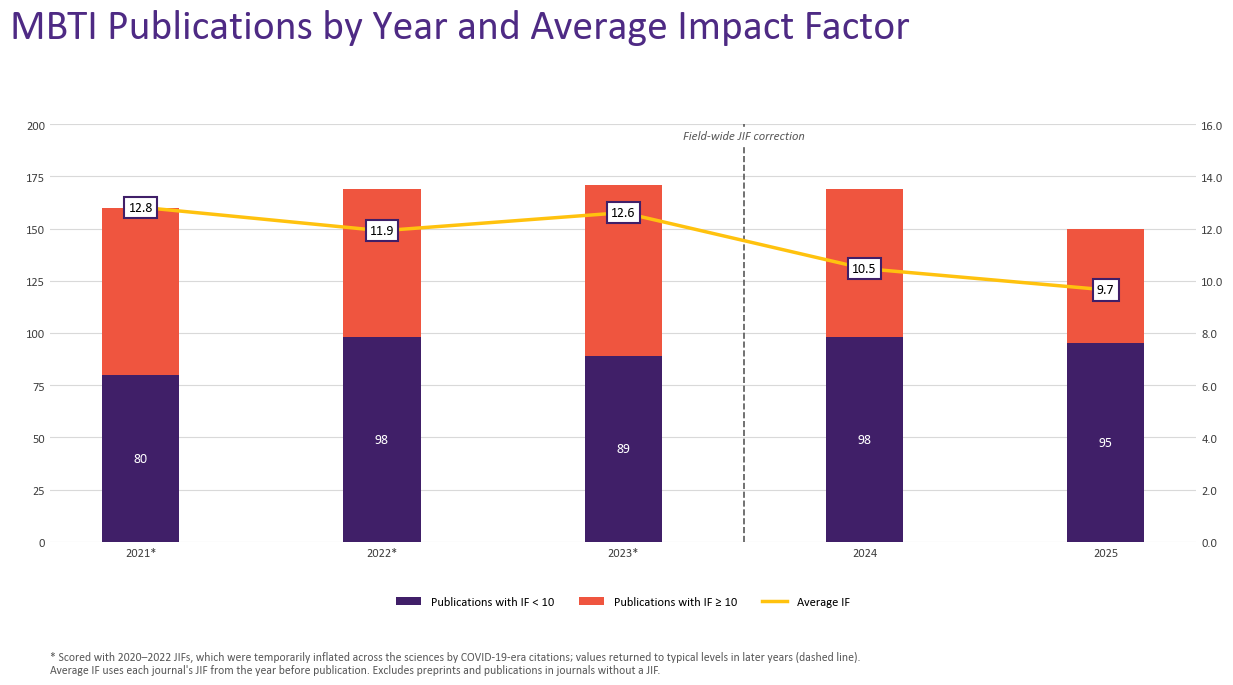

Publications in chart years without a JIF (not in bars or average): {2021: 23, 2022: 16, 2023: 35, 2024: 28, 2025: 46}


,year,n_publications,n_with_jif,n_below,n_at_or_above,average_jif,n_without_jif
0,2021,183,160,80,80,12.820075,23
1,2022,185,169,98,71,11.916834,16
2,2023,206,171,89,82,12.613450,35
3,2024,197,169,98,71,10.468047,28
4,2025,196,150,95,55,9.653333,46


In [11]:
# ---- Chart options (can also live in the first cell) ----
SHOW_DELTA_BOX       = False         # the "Average Impact Factor Δ" box on the right
SHOW_JIF_CORRECTION  = True          # dashed line + footnote marking the post-pandemic JIF correction
JIF_INFLATED_YEARS   = (2020, 2022)  # JCR years inflated by COVID-19 citations

cd = pubs_dedup[pubs_dedup["pub_year"].isin(CHART_YEARS)]
chart_data = (cd.assign(below=cd["jif"] < JIF_THRESHOLD, at_or_above=cd["jif"] >= JIF_THRESHOLD)
                .groupby("pub_year")
                .agg(n_publications=("pub_key", "count"), n_with_jif=("jif", "count"),
                     n_below=("below", "sum"), n_at_or_above=("at_or_above", "sum"),
                     average_jif=("jif", "mean"))
                .reindex(CHART_YEARS, fill_value=0).rename_axis("year").reset_index())
chart_data["n_without_jif"] = chart_data["n_publications"] - chart_data["n_with_jif"]
chart_data["average_jif"] = chart_data["average_jif"].replace(0, np.nan)
chart_data.to_csv(OUT_DIR / "05_chart_data.csv", index=False)

def pct_change(a, b):
    s = chart_data.set_index("year")["average_jif"]
    return (s[b] - s[a]) / s[a] * 100 if pd.notna(s.get(a)) and pd.notna(s.get(b)) and s[a] else np.nan

PURPLE, ORANGE, GOLD = "#401F68", "#EF553F", "#FFC20E"
TITLE_PURPLE, GREEN, RED, GRID, NOTE_GREY = "#4E2A84", "#00B050", "#C00000", "#D9D9D9", "#595959"
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Aptos", "Calibri", "Arial", "DejaVu Sans"]

def nice_ceiling(v, step):
    return max(step, step * np.ceil(v / step))

def make_chart(cdata):
    years = [int(y) for y in cdata["year"]]
    # publication years scored with inflated JIFs, and the first year after the correction
    inflated = [y for y in years if JIF_INFLATED_YEARS[0] <= y + JIF_YEAR_OFFSET <= JIF_INFLATED_YEARS[1]]
    first_corrected = JIF_INFLATED_YEARS[1] + 1 - JIF_YEAR_OFFSET
    show_note = SHOW_JIF_CORRECTION and bool(inflated)

    fig = plt.figure(figsize=(13.33, 7.2 if show_note else 6.8))
    fig.text(0.02, 0.96, CHART_TITLE, fontsize=30, color=TITLE_PURPLE, va="top")
    top = 0.80
    if CHART_SUBHEAD:
        fig.text(0.02, 0.86, CHART_SUBHEAD, fontsize=16, va="top")
        top = 0.74
    bottom = 0.22 if show_note else 0.16
    width = 0.50 if SHOW_DELTA_BOX else 0.86
    ax = fig.add_axes([0.05, bottom, width, top - bottom])
    x = np.arange(len(cdata)); w = 0.32
    lo, hi = cdata["n_below"].to_numpy(), cdata["n_at_or_above"].to_numpy()
    thr = f"{JIF_THRESHOLD:g}"
    ax.bar(x, lo, w, color=PURPLE, label=f"Publications with IF < {thr}", zorder=2)
    ax.bar(x, hi, w, bottom=lo, color=ORANGE, label=f"Publications with IF ≥ {thr}", zorder=2)
    for xi, a in zip(x, lo):
        if a: ax.text(xi, a / 2, f"{a:,}", ha="center", va="center", color="white", fontsize=10)
    labels = [f"{y}*" if (show_note and y in inflated) else str(y) for y in years]
    ax.set_xticks(x, labels)
    ax.set_ylim(0, nice_ceiling((lo + hi).max() * 1.12, 20))
    ax.yaxis.grid(True, color=GRID, lw=0.8); ax.set_axisbelow(True)
    ax.tick_params(length=0, labelsize=9, colors="#404040")
    for s in ax.spines.values(): s.set_visible(False)

    ax2 = ax.twinx()
    avg = cdata["average_jif"].to_numpy(dtype=float)
    ax2.plot(x, avg, color=GOLD, lw=2.5, label="Average IF", zorder=3)
    for xi, v in zip(x, avg):
        if not np.isnan(v):
            ax2.annotate(f"{v:.1f}", (xi, v), ha="center", va="center", fontsize=10, zorder=4,
                         bbox=dict(boxstyle="square,pad=0.3", fc="white", ec=PURPLE, lw=1.5))
    ax2.set_ylim(0, nice_ceiling(np.nanmax(avg) * 1.15, 2) if np.isfinite(np.nanmax(avg)) else 1)
    ax2.yaxis.set_major_formatter("{x:.1f}")
    ax2.tick_params(length=0, labelsize=9, colors="#404040")
    for s in ax2.spines.values(): s.set_visible(False)

    # dashed divider where publications switch from inflated to post-correction JIFs
    if show_note and first_corrected in years and years.index(first_corrected) > 0:
        xd = years.index(first_corrected) - 0.5
        ax.axvline(xd, color=NOTE_GREY, ls="--", lw=1.2, zorder=1)
        ax.text(xd, 0.985, "Field-wide JIF correction", transform=ax.get_xaxis_transform(),
                ha="center", va="top", fontsize=9, color=NOTE_GREY, style="italic",
                bbox=dict(boxstyle="square,pad=0.25", fc="white", ec="none"), zorder=5)

    h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
    fig.legend(h1 + h2, l1 + l2, loc="upper center", bbox_to_anchor=(0.05 + width / 2, bottom - 0.06),
               ncol=3, frameon=False, fontsize=9)

    if show_note:
        jif_years = f"{min(inflated) + JIF_YEAR_OFFSET}–{max(inflated) + JIF_YEAR_OFFSET}"
        basis = "the year before publication" if JIF_YEAR_OFFSET == -1 else (
                "the publication year" if JIF_YEAR_OFFSET == 0 else f"publication year {JIF_YEAR_OFFSET:+d}")
        fig.text(0.05, 0.035,
                 f"* Scored with {jif_years} JIFs, which were temporarily inflated across the sciences by "
                 f"COVID-19-era citations; values returned to typical levels in later years (dashed line).\n"
                 f"Average IF uses each journal's JIF from {basis}. Excludes preprints and publications "
                 f"in journals without a JIF.",
                 fontsize=8.5, color=NOTE_GREY, va="bottom", ha="left")

    if SHOW_DELTA_BOX:
        bax = fig.add_axes([0.60, 0.40, 0.34, 0.30]); bax.axis("off")
        bax.add_patch(Rectangle((0, 0), 1, 1, transform=bax.transAxes, fill=False, ec=PURPLE, lw=2.5, clip_on=False))
        bax.text(0.5, 0.80, "Average Impact Factor Δ", ha="center", va="center", fontsize=20, weight="bold")
        n = len(DELTA_PERIODS)
        for k, (a, b) in enumerate(DELTA_PERIODS):
            y = 0.52 - k * min(0.2, 0.42 / max(1, n - 1))
            p = pct_change(a, b)
            bax.text(0.63, y, f"{a}-{b}: ", ha="right", va="center", fontsize=20)
            bax.text(0.63, y, "n/a" if np.isnan(p) else f"{p:+.0f}%", ha="left", va="center", fontsize=20,
                     weight="bold", color=GREEN if (not np.isnan(p) and p >= 0) else RED)
    return fig

fig = make_chart(chart_data)
fig.savefig(OUT_DIR / "06_publications_by_year_avg_jif.png", dpi=200, bbox_inches="tight")
fig.savefig(OUT_DIR / "06_publications_by_year_avg_jif.svg", bbox_inches="tight")
plt.show()

print("Publications in chart years without a JIF (not in bars or average):",
      dict(zip(chart_data["year"], chart_data["n_without_jif"])))
chart_data



## Output files
| File | Contents |
|---|---|
| `01_awards.csv` | One row per award: route taken (RePORTER / Scopus / not searched), variants searched, publication count |
| `01_publications_by_grant.csv` | Every grant × publication match (Part 1 checkpoint) |
| `01_excluded_matches.csv` | Matches dropped by a safeguard, with the reason |
| `01_scopus_query_log.csv` | Exact Scopus query and hit count per award |
| `02_issn_list.txt`, `02_journal_issns_for_jcr.csv` | ISSNs for the JIF export |
| `02_publications_without_issn.csv` | Matches with no ISSN (books, preprints, etc.) |
| `03_publications_by_grant_with_jif.csv` | Grant × publication rows with JIF (duplicates kept) |
| `04_publications_deduplicated_with_jif.csv` | One row per publication, with all linked grants |
| `05_chart_data.csv`, `06_…png/svg` | Chart numbers and image (the CSV lets you rebuild it natively in PowerPoint) |